In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [8]:
df = pd.read_csv("uber.csv")

print(df.head())
print(df.info())
print(df.isnull().sum())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [9]:
df.drop(columns=['Unnamed: 0', 'key'], errors='ignore', inplace=True)

df.dropna(inplace=True)

df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], errors='coerce', utc=True
)

df.dropna(subset=['pickup_datetime'], inplace=True)

df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year

df.drop(columns=['pickup_datetime'], inplace=True)

df = df[
    (df['fare_amount'] > 0) &
    (df['passenger_count'] > 0) &
    (df['pickup_latitude'].between(-90, 90)) &
    (df['dropoff_latitude'].between(-90, 90)) &
    (df['pickup_longitude'].between(-180, 180)) &
    (df['dropoff_longitude'].between(-180, 180))
]

print(df.head())

   fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0          7.5        -73.999817        40.738354         -73.999512   
1          7.7        -73.994355        40.728225         -73.994710   
2         12.9        -74.005043        40.740770         -73.962565   
3          5.3        -73.976124        40.790844         -73.965316   
4         16.0        -73.925023        40.744085         -73.973082   

   dropoff_latitude  passenger_count  hour  day  month  year  
0         40.723217                1    19    7      5  2015  
1         40.750325                1    20   17      7  2009  
2         40.772647                1    21   24      8  2009  
3         40.803349                3     8   26      6  2009  
4         40.761247                5    17   28      8  2014  


In [10]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[
    (df['fare_amount'] >= lower) &
    (df['fare_amount'] <= upper)
]

print("Dataset shape after removing outliers:", df.shape)

Dataset shape after removing outliers: (182137, 10)


                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.000134        -0.000590   
pickup_longitude      0.000134          1.000000        -0.980169   
pickup_latitude      -0.000590         -0.980169         1.000000   
dropoff_longitude    -0.000964          0.955071        -0.942673   
dropoff_latitude      0.000545         -0.942984         0.962609   
passenger_count       0.012003         -0.000804        -0.000640   
hour                 -0.013296          0.002083        -0.002278   
day                   0.007145          0.003853        -0.007158   
month                 0.026181         -0.002982         0.003996   
year                  0.135636          0.009623        -0.011798   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
fare_amount                -0.000964          0.000545         0.012003   
pickup_longitude            0.955071         -0.942984        -0.000804   
pickup_latitude

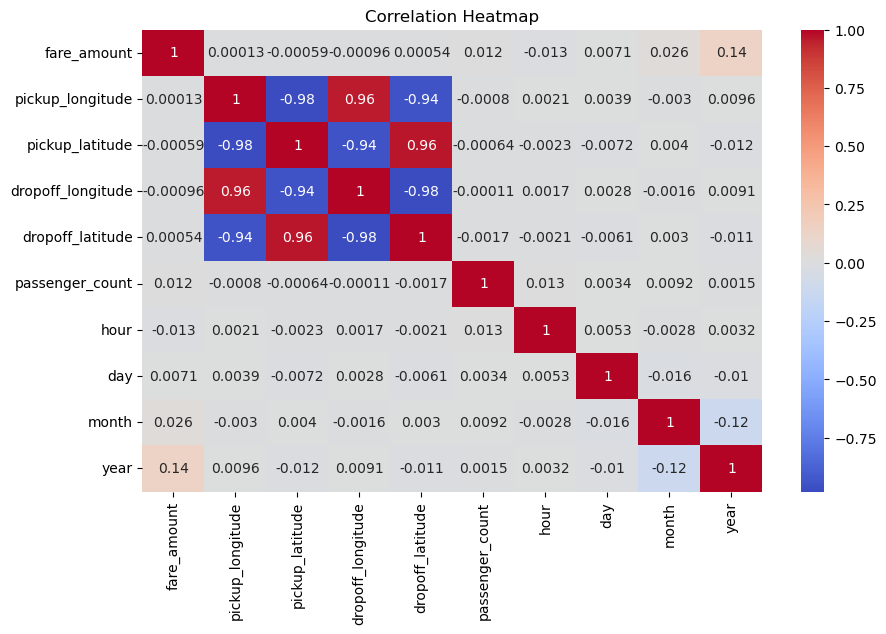

In [20]:
correlation = df.corr(numeric_only=True)

print(correlation)

plt.figure(figsize=(10, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [22]:
X = df.drop('fare_amount', axis=1)
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)

(145709, 9)


In [23]:
lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

In [24]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [25]:
def evaluate_model(name, y_test, predictions):
    print(name)
    print("R2 Score:", r2_score(y_test, predictions))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
    print("MAE:", mean_absolute_error(y_test, predictions))
    print()

evaluate_model("Linear Regression", y_test, lr_pred)
evaluate_model("Random Forest Regression", y_test, rf_pred)

Linear Regression
R2 Score: 0.01946808198147687
RMSE: 4.096497127677257
MAE: 3.2422629584415255

Random Forest Regression
R2 Score: 0.7573483517572337
RMSE: 2.0378556126794396
MAE: 1.3960527740304423



In [26]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [
        r2_score(y_test, lr_pred),
        r2_score(y_test, rf_pred)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, lr_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred))
    ],
    'MAE': [
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, rf_pred)
    ]
})

print(results)

               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.019468  4.096497  3.242263
1      Random Forest  0.757348  2.037856  1.396053


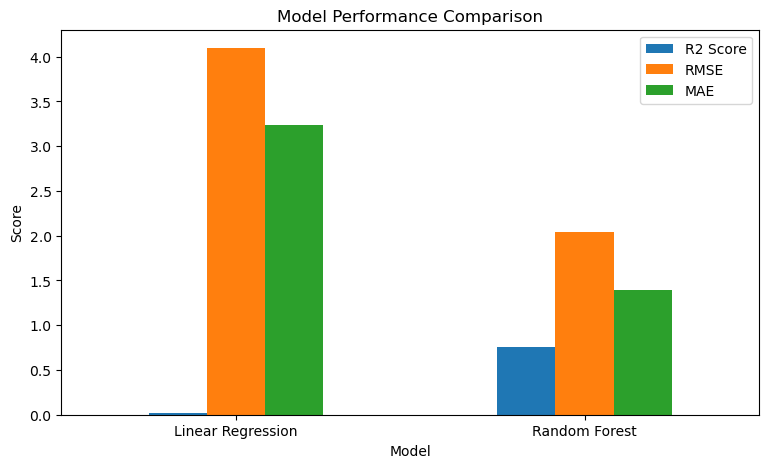

In [27]:
results.set_index('Model')[['R2 Score', 'RMSE', 'MAE']].plot(
    kind='bar', figsize=(9, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()